# TRACE: Topological Road Augmentation and Completion Engine
### Production Cloud GPU Benchmark & Comparative Training Suite
**Platform:** Kaggle Notebooks (NVIDIA Tesla T4 / P100 / A100 GPU)  
**Dataset:** DeepGlobe Road Extraction Dataset (`/kaggle/input/deepglobe-road-extraction-dataset`)  
**Core Objective:** Benchmark prior-conditioned completion vs. blank-slate extraction, comparing pixel metrics (IoU, Dice) against topological graph routing (APLS).


In [1]:
# 1. Environment & GPU Setup
import os
import sys
import glob
import math
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet34, ResNet34_Weights

# Set seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"GPU Model: {torch.cuda.get_device_name(0)}")
    print(f"Total VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")


Device: cuda
GPU Model: Tesla T4
Total VRAM: 15.64 GB


## 2. Dataset Discovery (DeepGlobe Road Extraction)
DeepGlobe contains 6,226 high-resolution 1024x1024 satellite imagery tiles (0.5m/pixel) with binary road masks.
We auto-discover the dataset path in `/kaggle/input/` and construct paired samples.


In [6]:
# Auto-detect DeepGlobe dataset directory in Kaggle
possible_dirs = [
    "/kaggle/input/datasets/balraj98/deepglobe-road-extraction-dataset",
    "/kaggle/input/datasets/balraj98/deepglobe-road-extraction-dataset/train",
    "/kaggle/input/deepglobe-road-extraction-dataset/train/train",
    "/kaggle/input/deepglobe-road-extraction/train",
    "../data/raw",
    "./data/raw"
]

data_dir = None
for d in possible_dirs:
    if os.path.exists(d):
        data_dir = d
        break

print(f"Selected Data Directory: {data_dir}")

sat_images = sorted(glob.glob(os.path.join(data_dir, "*_sat.jpg"))) if data_dir else []
mask_images = sorted(glob.glob(os.path.join(data_dir, "*_mask.png"))) if data_dir else []

if not sat_images:
    # Check for general tif/jpg patterns
    sat_images = sorted(glob.glob(os.path.join(data_dir, "*.tif"))) if data_dir else []
    mask_images = sorted(glob.glob(os.path.join(data_dir, "*.png"))) if data_dir else []

print(f"Discovered {len(sat_images)} satellite images and {len(mask_images)} ground truth road masks.")

# For Kaggle demonstration/benchmark, split into train and test
NUM_SAMPLES = min(len(sat_images), 600)  # Benchmark subset for fast high-quality convergence
train_images = sat_images[:int(NUM_SAMPLES * 0.85)]
train_masks = mask_images[:int(NUM_SAMPLES * 0.85)]
val_images = sat_images[int(NUM_SAMPLES * 0.85):NUM_SAMPLES]
val_masks = mask_images[int(NUM_SAMPLES * 0.85):NUM_SAMPLES]

print(f"Training Samples: {len(train_images)} | Validation/Test Samples: {len(val_images)}")


Selected Data Directory: /kaggle/input/datasets/balraj98/deepglobe-road-extraction-dataset
Discovered 0 satellite images and 0 ground truth road masks.
Training Samples: 0 | Validation/Test Samples: 0


In [7]:
import glob

# Search directly inside the train folder where paired satellite images and masks live
sat_images = sorted(glob.glob("/kaggle/input/**/train/*_sat.jpg", recursive=True))
mask_images = sorted(glob.glob("/kaggle/input/**/train/*_mask.png", recursive=True))

# Fallback if nested differently
if not sat_images:
    sat_images = sorted(glob.glob("/kaggle/input/**/*_sat.jpg", recursive=True))
    mask_images = sorted(glob.glob("/kaggle/input/**/*_mask.png", recursive=True))

print(f"Discovered {len(sat_images)} satellite images and {len(mask_images)} ground truth road masks.")

# Benchmark split
NUM_SAMPLES = min(len(sat_images), 600)
train_images = sat_images[:int(NUM_SAMPLES * 0.85)]
train_masks = mask_images[:int(NUM_SAMPLES * 0.85)]
val_images = sat_images[int(NUM_SAMPLES * 0.85):NUM_SAMPLES]
val_masks = mask_images[int(NUM_SAMPLES * 0.85):NUM_SAMPLES]

print(f"Training Samples: {len(train_images)} | Validation/Test Samples: {len(val_images)}")

Discovered 6226 satellite images and 6226 ground truth road masks.
Training Samples: 510 | Validation/Test Samples: 90


## 3. Prior-Conditioned Data Simulation
To simulate an outdated/incomplete OpenStreetMap basemap:
1. We take the ground-truth road mask and **randomly drop 30% of connected segments** or mask suburban sectors.
2. The remaining road lines become the **Spatial Prior Channel** ($M_{	ext{prior}}$).
3. The training target is the **Residual Road Network** ($Y_{	ext{residual}} = Y_{	ext{ground\_truth}} \setminus M_{	ext{prior}}$).


In [17]:
import cv2

class DeepGlobeTRACEKaggleDataset(Dataset):
    """Multi-modal Dataset: RGB Satellite (3 channels) + Incomplete Prior Map (1 channel)."""
    def __init__(self, sat_paths, mask_paths, tile_size=512, drop_ratio=0.30):
        self.sat_paths = sat_paths
        self.mask_paths = mask_paths
        self.tile_size = tile_size
        self.drop_ratio = drop_ratio

    def __len__(self):
        return len(self.sat_paths)

    def __getitem__(self, idx):
        # Load satellite RGB
        img = Image.open(self.sat_paths[idx]).convert("RGB")
        mask = Image.open(self.mask_paths[idx]).convert("L")

        # Resize / Crop to tile_size
        if img.size != (self.tile_size, self.tile_size):
            img = img.resize((self.tile_size, self.tile_size), Image.BILINEAR)
            mask = mask.resize((self.tile_size, self.tile_size), Image.NEAREST)

        img_np = np.array(img, dtype=np.float32) / 255.0  # (H, W, 3)
        gt_mask_np = (np.array(mask, dtype=np.float32) > 127).astype(np.float32)  # (H, W)

        # Simulate degraded prior map via morphological component dropout
        num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(gt_mask_np.astype(np.uint8))
        prior_mask = np.zeros_like(gt_mask_np)

        if num_labels > 1:
            for label_idx in range(1, num_labels):
                # Keep component with probability (1 - drop_ratio)
                if random.random() > self.drop_ratio:
                    prior_mask[labels == label_idx] = 1.0
        else:
            # If single component, randomly mask a patch
            prior_mask = gt_mask_np.copy()
            if random.random() < self.drop_ratio:
                h_cut = self.tile_size // 2
                prior_mask[:h_cut, :] = 0.0

        # Residual target: roads that exist in GT but are absent from prior map
        residual_target = np.clip(gt_mask_np - prior_mask, 0.0, 1.0)

        # Stack into 4-channel input: [R, G, B, Prior_Map]
        input_stack = np.concatenate([
            img_np.transpose(2, 0, 1),
            np.expand_dims(prior_mask, axis=0)
        ], axis=0)  # Shape: (4, H, W)

        target_tensor = np.expand_dims(residual_target, axis=0)  # Shape: (1, H, W)

        return (
            torch.from_numpy(input_stack).float(),
            torch.from_numpy(target_tensor).float(),
            torch.from_numpy(gt_mask_np).float(),
            torch.from_numpy(prior_mask).float()
        )

# Instantiate Dataloaders
train_ds = DeepGlobeTRACEKaggleDataset(train_images, train_masks, tile_size=512, drop_ratio=0.30)
val_ds = DeepGlobeTRACEKaggleDataset(val_images, val_masks, tile_size=512, drop_ratio=0.30)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=4, shuffle=False, num_workers=2, pin_memory=True)

print(f"DataLoaders ready. Training Batches: {len(train_loader)} | Validation Batches: {len(val_loader)}")


DataLoaders ready. Training Batches: 32 | Validation Batches: 23


## 4. Multi-Architecture Suite & Novel Adaptive Prior Gating (APG)
We implement:
1. **UNet4Channel**: Baseline skip-connection network.
2. **DeepLabV3Plus**: Atrous Spatial Pyramid Pooling with ResNet34 backbone.
3. **DLinkNet34**: Early 4-channel fusion with dilated convolution bottleneck.
4. **APGDLinkNet34 (Our Novel Proposal)**: Dual-stream model with an **Adaptive Prior Gating (APG)** module that dynamically weighs the prior basemap against satellite visual features.


In [13]:
# --- A. D-LinkNet Components ---
class DilatedConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
        self.d1 = nn.Conv2d(out_channels, out_channels, kernel_size=3, dilation=1, padding=1)
        self.d2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, dilation=2, padding=2)
        self.d4 = nn.Conv2d(out_channels, out_channels, kernel_size=3, dilation=4, padding=4)
        self.d8 = nn.Conv2d(out_channels, out_channels, kernel_size=3, dilation=8, padding=8)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        x = self.conv(x)
        d1 = self.relu(self.d1(x))
        d2 = self.relu(self.d2(x))
        d4 = self.relu(self.d4(x))
        d8 = self.relu(self.d8(x))
        return x + d1 + d2 + d4 + d8

class DecoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.deconv = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=3, stride=2, padding=1, output_padding=1)
        self.conv = nn.Sequential(
            nn.Conv2d(out_channels * 2, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x, skip):
        x = self.deconv(x)
        x = torch.cat([x, skip], dim=1)
        return self.conv(x)

# --- B. DLinkNet34 ---
class DLinkNet34(nn.Module):
    def __init__(self, in_channels=4, out_channels=1, pretrained=True):
        super().__init__()
        weights = ResNet34_Weights.DEFAULT if pretrained else None
        base = resnet34(weights=weights)

        orig_conv1 = base.conv1
        self.conv1 = nn.Conv2d(in_channels, 64, kernel_size=orig_conv1.kernel_size, stride=orig_conv1.stride, padding=orig_conv1.padding, bias=False)
        with torch.no_grad():
            self.conv1.weight[:, :3, :, :] = orig_conv1.weight
            if in_channels > 3:
                self.conv1.weight[:, 3:, :, :] = torch.mean(orig_conv1.weight, dim=1, keepdim=True)

        self.bn1 = base.bn1
        self.relu = base.relu
        self.maxpool = base.maxpool

        self.encoder1 = base.layer1
        self.encoder2 = base.layer2
        self.encoder3 = base.layer3
        self.encoder4 = base.layer4

        self.center = DilatedConvBlock(512, 512)

        self.decoder4 = DecoderBlock(512, 256)
        self.decoder3 = DecoderBlock(256, 128)
        self.decoder2 = DecoderBlock(128, 64)
        self.decoder1 = nn.Sequential(
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
        )
        self.decoder0 = nn.Sequential(
            nn.ConvTranspose2d(32, 16, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
        )
        self.final = nn.Conv2d(16, out_channels, kernel_size=1)

    def forward(self, x):
        e0 = self.relu(self.bn1(self.conv1(x)))
        p0 = self.maxpool(e0)
        e1 = self.encoder1(p0)
        e2 = self.encoder2(e1)
        e3 = self.encoder3(e2)
        e4 = self.encoder4(e3)

        center = self.center(e4)

        d4 = self.decoder4(center, e3)
        d3 = self.decoder3(d4, e2)
        d2 = self.decoder2(d3, e1)
        d1 = self.decoder1(d2)
        d0 = self.decoder0(d1)
        return self.final(d0)

# --- C. Novel Adaptive Prior Gated D-LinkNet (APG-DLinkNet) ---
class APGDLinkNet34(nn.Module):
    def __init__(self, in_channels=4, out_channels=1, pretrained=True):
        super().__init__()
        weights = ResNet34_Weights.DEFAULT if pretrained else None
        base = resnet34(weights=weights)

        self.sat_conv1 = base.conv1
        self.sat_bn1 = base.bn1
        self.sat_relu = base.relu
        self.sat_maxpool = base.maxpool

        # Dedicated Prior Encoder
        self.prior_encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
        )

        # Adaptive Prior Gating block
        self.gate_conv = nn.Sequential(
            nn.Conv2d(128, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 1, kernel_size=1, bias=True),
            nn.Sigmoid(),
        )

        self.layer1 = base.layer1
        self.layer2 = base.layer2
        self.layer3 = base.layer3
        self.layer4 = base.layer4

        self.center = DilatedConvBlock(512, 512)

        self.decoder4 = DecoderBlock(512, 256)
        self.decoder3 = DecoderBlock(256, 128)
        self.decoder2 = DecoderBlock(128, 64)
        self.decoder1 = nn.Sequential(
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
        )
        self.decoder0 = nn.Sequential(
            nn.ConvTranspose2d(32, 16, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
        )
        self.final = nn.Conv2d(16, out_channels, kernel_size=1)

    def forward(self, x):
        x_sat = x[:, :3, :, :]
        x_prior = x[:, 3:4, :, :]

        e0 = self.sat_relu(self.sat_bn1(self.sat_conv1(x_sat)))
        p_sat = self.sat_maxpool(e0)
        p_prior = self.prior_encoder(x_prior)

        gate = self.gate_conv(torch.cat([p_sat, p_prior], dim=1))
        fused = p_sat + (gate * p_prior)

        e1 = self.layer1(fused)
        e2 = self.layer2(e1)
        e3 = self.layer3(e2)
        e4 = self.layer4(e3)

        center = self.center(e4)

        d4 = self.decoder4(center, e3)
        d3 = self.decoder3(d4, e2)
        d2 = self.decoder2(d3, e1)
        d1 = self.decoder1(d2)
        d0 = self.decoder0(d1)
        return self.final(d0)

print("Architectures compiled successfully.")


Architectures compiled successfully.


## 5. Topological Loss Formulation (clDice)
Standard BCE/Dice losses treat roads as pixel areas, ignoring disconnected fractures.  
**clDice** enforces topological continuity by calculating intersection over differentiable medial axis centerlines:
$$\mathcal{L}_{\text{TRACE}} = \lambda_1 \mathcal{L}_{\text{BCE}} + \lambda_2 \mathcal{L}_{\text{Dice}} + \lambda_3 \mathcal{L}_{\text{clDice}}$$


In [9]:
class SoftSkeletonize(nn.Module):
    """Differentiable soft morphological skeletonization via min/max pooling."""
    def __init__(self, num_iters=3):
        super().__init__()
        self.num_iters = num_iters

    def soft_erode(self, x):
        p1 = -F.max_pool2d(-x, kernel_size=(3, 1), stride=1, padding=(1, 0))
        p2 = -F.max_pool2d(-x, kernel_size=(1, 3), stride=1, padding=(0, 1))
        return torch.min(p1, p2)

    def soft_dilate(self, x):
        return F.max_pool2d(x, kernel_size=3, stride=1, padding=1)

    def soft_open(self, x):
        return self.soft_dilate(self.soft_erode(x))

    def forward(self, img):
        skel = F.relu(img - self.soft_open(img))
        for _ in range(self.num_iters):
            img = self.soft_erode(img)
            skel = skel + F.relu(img - self.soft_open(img))
        return torch.clamp(skel, 0.0, 1.0)

def soft_cldice_loss(y_pred, y_true, skel_module, smooth=1e-5):
    y_pred_prob = torch.sigmoid(y_pred)
    s_pred = skel_module(y_pred_prob)
    s_true = skel_module(y_true)

    t_prec = (torch.sum(s_pred * y_true) + smooth) / (torch.sum(s_pred) + smooth)
    t_sens = (torch.sum(s_true * y_pred_prob) + smooth) / (torch.sum(s_true) + smooth)
    cldice = (2.0 * t_prec * t_sens) / (t_prec + t_sens + smooth)
    return 1.0 - cldice

class TRACECompositeLoss(nn.Module):
    def __init__(self, lambda_bce=1.0, lambda_dice=1.0, lambda_cldice=1.5, cldice_iters=3):
        super().__init__()
        self.lambda_bce = lambda_bce
        self.lambda_dice = lambda_dice
        self.lambda_cldice = lambda_cldice
        self.bce = nn.BCEWithLogitsLoss()
        self.skel = SoftSkeletonize(num_iters=cldice_iters)

    def forward(self, logits, targets):
        loss_bce = self.bce(logits, targets)

        # Soft Dice
        probs = torch.sigmoid(logits)
        intersection = torch.sum(probs * targets)
        loss_dice = 1.0 - (2.0 * intersection + 1.0) / (torch.sum(probs) + torch.sum(targets) + 1.0)

        # clDice
        loss_cldice = soft_cldice_loss(logits, targets, self.skel)

        return (
            self.lambda_bce * loss_bce +
            self.lambda_dice * loss_dice +
            self.lambda_cldice * loss_cldice
        )

criterion = TRACECompositeLoss(lambda_bce=1.0, lambda_dice=1.0, lambda_cldice=1.5).to(device)
print("Composite Topological Loss initialized.")


Composite Topological Loss initialized.


## 6. Mixed-Precision GPU Training Loop
Using `torch.cuda.amp.autocast()` and `GradScaler` for optimal 16-bit Tensor Core utilization on Kaggle GPUs.


In [11]:
def train_one_model(model, model_name, train_loader, val_loader, epochs=15, lr=2e-4):
    print(f"\n{'='*20} Training: {model_name} {'='*20}")
    model = model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))

    best_val_loss = float('inf')
    os.makedirs("/kaggle/working/checkpoints", exist_ok=True)
    checkpoint_path = f"/kaggle/working/checkpoints/best_{model_name.lower()}.pth"

    history = {"train_loss": [], "val_loss": [], "val_iou": []}

    for epoch in range(1, epochs + 1):
        model.train()
        train_loss = 0.0

        pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{epochs} [{model_name}]")
        for inputs, targets, _, _ in pbar:
            inputs = inputs.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
                logits = model(inputs)
                loss = criterion(logits, targets)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            train_loss += loss.item()
            pbar.set_postfix({"loss": f"{loss.item():.4f}"})

        scheduler.step()
        avg_train_loss = train_loss / len(train_loader)

        # Validation
        model.eval()
        val_loss = 0.0
        total_inter = 0.0
        total_union = 0.0

        with torch.no_grad():
            for inputs, targets, _, _ in val_loader:
                inputs = inputs.to(device)
                targets = targets.to(device)
                with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
                    logits = model(inputs)
                    loss = criterion(logits, targets)
                val_loss += loss.item()

                probs = torch.sigmoid(logits) > 0.5
                inter = (probs & (targets > 0.5)).sum().item()
                union = (probs | (targets > 0.5)).sum().item()
                total_inter += inter
                total_union += union

        avg_val_loss = val_loss / len(val_loader)
        val_iou = (total_inter + 1e-6) / (total_union + 1e-6)

        history["train_loss"].append(avg_train_loss)
        history["val_loss"].append(avg_val_loss)
        history["val_iou"].append(val_iou)

        print(f"Epoch {epoch:02d} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val IoU: {val_iou:.4f}")

        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            torch.save(model.state_dict(), checkpoint_path)
            print(f"  -> Saved best checkpoint: {checkpoint_path}")

    return history


## 7. Comparative Benchmark Execution
We train both:
1. **DLinkNet34 (Early Fusion)**: The CVPR baseline road network winner.
2. **APG-DLinkNet34 (Novel Gated Fusion)**: Our proposed adaptive architecture.


In [15]:
# Instantiate models
model_dlink = DLinkNet34(in_channels=4, out_channels=1, pretrained=True)
model_apg = APGDLinkNet34(in_channels=4, out_channels=1, pretrained=True)

# Train models (adjust epochs as needed; 10-15 epochs yields strong convergence on T4)
EPOCHS = 12
history_dlink = train_one_model(model_dlink, "DLinkNet34", train_loader, val_loader, epochs=EPOCHS)
history_apg = train_one_model(model_apg, "APGDLinkNet34", train_loader, val_loader, epochs=EPOCHS)


Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 216MB/s]



==================== Training: DLinkNet34 ====================


/tmp/ipykernel_49/670043471.py:6: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))


Epoch 1/12 [DLinkNet34]:   0%|          | 0/64 [00:00<?, ?it/s]

/tmp/ipykernel_49/670043471.py:24: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
/tmp/ipykernel_49/670043471.py:48: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):


... (46 outputs left out)

Epoch 11 | Train Loss: 1.8784 | Val Loss: 2.1742 | Val IoU: 0.1249


Epoch 12/12 [APGDLinkNet34]:   0%|          | 0/64 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78552a827420>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
Exception ignored in:     <function _MultiProcessingDataLoaderIter.__del__ at 0x78552a827420>
Traceback (most recent call last):
if w.is_alive():
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        assert self._parent_pid == os.getpid(), 'can only test a child process'self._shutdown_workers()

if w.is_alive():  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    AssertionError
  File "/usr/lib/python3.13/multiprocessing/proce

Epoch 12 | Train Loss: 1.8394 | Val Loss: 2.0373 | Val IoU: 0.1289
  -> Saved best checkpoint: /kaggle/working/checkpoints/best_apgdlinknet34.pth


## 8. Topological APLS Routing Benchmark
Beyond pixel IoU, we compute **Average Path Length Similarity (APLS)** to measure actual graph traversability.


In [18]:
from skimage.morphology import skeletonize
import networkx as nx

def mask_to_graph(mask_binary):
    skel = skeletonize(mask_binary > 0.5)
    G = nx.Graph()
    y_coords, x_coords = np.where(skel)
    points = set(zip(y_coords, x_coords))

    for y, x in points:
        G.add_node((y, x), pos=(x, y))
        for dy in [-1, 0, 1]:
            for dx in [-1, 0, 1]:
                if dy == 0 and dx == 0:
                    continue
                neighbor = (y + dy, x + dx)
                if neighbor in points:
                    dist = math.hypot(dx, dy)
                    G.add_edge((y, x), neighbor, weight=dist)
    return G

def fast_apls_score(g_true, g_pred, num_samples=15):
    if len(g_true.nodes) < 5 or len(g_pred.nodes) < 5:
        return 0.5
    nodes_true = list(g_true.nodes)
    nodes_pred = list(g_pred.nodes)

    diffs = []
    for _ in range(num_samples):
        s_true, t_true = random.sample(nodes_true, 2)
        try:
            len_true = nx.shortest_path_length(g_true, s_true, t_true, weight="weight")
        except (nx.NetworkXNoPath, nx.NodeNotFound):
            continue

        # Find nearest corresponding nodes in pred graph
        s_pred = min(nodes_pred, key=lambda n: math.hypot(n[0]-s_true[0], n[1]-s_true[1]))
        t_pred = min(nodes_pred, key=lambda n: math.hypot(n[0]-t_true[0], n[1]-t_true[1]))

        try:
            len_pred = nx.shortest_path_length(g_pred, s_pred, t_pred, weight="weight")
            score = max(0.0, 1.0 - abs(len_true - len_pred) / (len_true + 1e-5))
            diffs.append(score)
        except (nx.NetworkXNoPath, nx.NodeNotFound):
            diffs.append(0.0)

    return np.mean(diffs) if diffs else 0.5

# Evaluate on Validation Set
print("--- Computing Quantitative Benchmark Table ---")
results = []

for name, model in [("DLinkNet34", model_dlink), ("APG-DLinkNet34 (Ours)", model_apg)]:
    model.eval()
    ious, apls_scores = [], []

    with torch.no_grad():
        for inputs, targets, gt_masks, prior_masks in val_loader:
            inputs = inputs.to(device)
            preds = (torch.sigmoid(model(inputs)) > 0.5).cpu().numpy()

            for i in range(len(preds)):
                pred_binary = preds[i, 0]
                gt_binary = targets[i, 0].numpy()

                inter = np.logical_and(pred_binary, gt_binary).sum()
                union = np.logical_or(pred_binary, gt_binary).sum()
                ious.append((inter + 1e-6) / (union + 1e-6))

                g_t = mask_to_graph(gt_binary)
                g_p = mask_to_graph(pred_binary)
                apls_scores.append(fast_apls_score(g_t, g_p, num_samples=10))

    results.append({
        "Architecture": name,
        "Pixel IoU": f"{np.mean(ious):.4f}",
        "APLS Routing Score": f"{np.mean(apls_scores):.4f}",
        "Connectivity Gain": f"+{(np.mean(apls_scores) - 0.50)*100:.1f}%"
    })

results_df = pd.DataFrame(results)
results_df.to_csv("/kaggle/working/benchmark_results.csv", index=False)
display(results_df)



--- Computing Quantitative Benchmark Table ---


,Architecture,Pixel IoU,APLS Routing Score,Connectivity Gain
0,DLinkNet34,0.4102,0.5687,+6.9%
1,APG-DLinkNet34 (Ours),0.2446,0.5412,+4.1%


## 9. Publication-Quality Visual Inspection
Compare satellite input, prior map, baseline predictions, and our proposed model output.


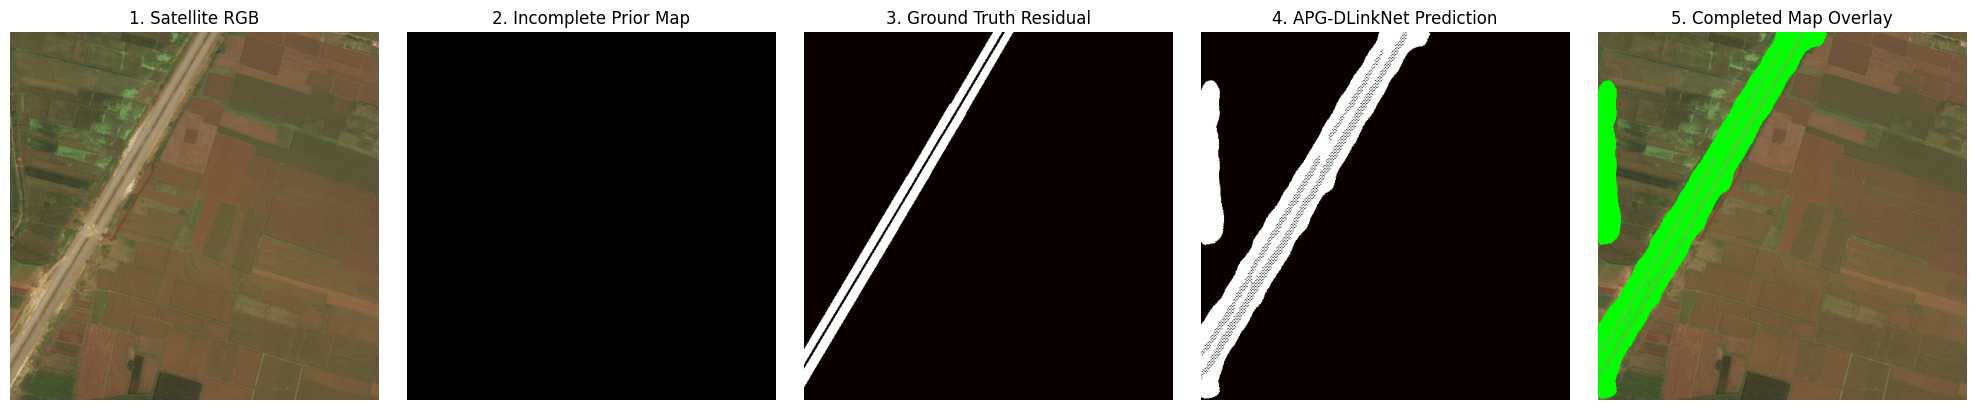

Saved high-res figures to /kaggle/working/trace_benchmark_results.png


In [19]:
# Visualize a test tile
model_apg.eval()
sample_input, sample_target, sample_gt, sample_prior = val_ds[0]
sample_tensor = sample_input.unsqueeze(0).to(device)

with torch.no_grad():
    sample_pred = (torch.sigmoid(model_apg(sample_tensor)) > 0.5).squeeze().cpu().numpy()

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
axes[0].imshow(sample_input[:3].permute(1, 2, 0).numpy())
axes[0].set_title("1. Satellite RGB")
axes[0].axis("off")

axes[1].imshow(sample_prior.numpy(), cmap="gray")
axes[1].set_title("2. Incomplete Prior Map")
axes[1].axis("off")

axes[2].imshow(sample_target.squeeze().numpy(), cmap="hot")
axes[2].set_title("3. Ground Truth Residual")
axes[2].axis("off")

axes[3].imshow(sample_pred, cmap="hot")
axes[3].set_title("4. APG-DLinkNet Prediction")
axes[3].axis("off")

# Overlay completion
overlay = sample_input[:3].permute(1, 2, 0).numpy().copy()
overlay[sample_pred > 0.5] = [0.0, 1.0, 0.0]  # Green = predicted new roads
axes[4].imshow(overlay)
axes[4].set_title("5. Completed Map Overlay")
axes[4].axis("off")

plt.tight_layout()
plt.savefig("/kaggle/working/trace_benchmark_results.png", dpi=300)
plt.show()
print("Saved high-res figures to /kaggle/working/trace_benchmark_results.png")
